<a href="https://colab.research.google.com/github/mrym-abed/Decision-Dependent-Contextual-Optimization/blob/main/NYC_Subway.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **NYC Subway Infrastructure Security Game**

## **Step 1: Data Upload and Loading**

In [ ]:

from google.colab import files
import pandas as pd
from pathlib import Path

# Upload CSV or Excel file
uploaded = files.upload()

file_name = next(iter(uploaded))
extension = Path(file_name).suffix.lower()

# Read original data
if extension == ".csv":
    df = pd.read_csv(
        file_name,
        encoding="utf-8-sig",
        low_memory=False,
        dtype={"station_complex_id": "string"}
    )

elif extension in [".xlsx", ".xls"]:
    df = pd.read_excel(
        file_name,
        dtype={"station_complex_id": "string"}
    )

else:
    raise ValueError("Please upload a CSV or Excel file.")

print("File:", file_name)
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nOriginal column names:")
print(df.columns.tolist())

display(df.head(10))

Saving MTA_Subway_Hourly_Ridership__2020-2024_20261112.csv to MTA_Subway_Hourly_Ridership__2020-2024_20261112.csv
File: MTA_Subway_Hourly_Ridership__2020-2024_20261112.csv
Number of rows: 1450932
Number of columns: 12

Original column names:
['transit_timestamp', 'transit_mode', 'station_complex_id', 'station_complex', 'borough', 'payment_method', 'fare_class_category', 'ridership', 'transfers', 'latitude', 'longitude', 'Georeference']


,transit_timestamp,transit_mode,station_complex_id,station_complex,borough,payment_method,fare_class_category,ridership,transfers,latitude,longitude,Georeference
0,12/25/2024 09:00:00 AM,subway,309,103 St (1),Manhattan,omny,OMNY - Students,3,0,40.799446,-73.968376,POINT (-73.968376 40.799446)
1,12/25/2024 11:00:00 AM,subway,10,"49 St (N,R,W)",Manhattan,omny,OMNY - Students,2,0,40.759900,-73.984140,POINT (-73.98414 40.7599)
2,12/25/2024 04:00:00 PM,subway,394,110 St (6),Manhattan,omny,OMNY - Full Fare,71,0,40.795020,-73.944250,POINT (-73.94425 40.79502)
3,12/25/2024 04:00:00 PM,subway,150,155 St (C),Manhattan,omny,OMNY - Full Fare,15,0,40.830517,-73.941510,POINT (-73.94151 40.830517)
4,12/25/2024 01:00:00 AM,subway,10,"49 St (N,R,W)",Manhattan,omny,OMNY - Students,6,0,40.759900,-73.984140,POINT (-73.98414 40.7599)
5,12/25/2024 07:00:00 PM,subway,316,50 St (1),Manhattan,omny,OMNY - Full Fare,550,2,40.761726,-73.983850,POINT (-73.98385 40.761726)
6,12/25/2024 04:00:00 AM,subway,299,Dyckman St (1),Manhattan,metrocard,Metrocard - Full Fare,8,0,40.860530,-73.925540,POINT (-73.92554 40.86053)
7,12/25/2024 12:00:00 PM,subway,619,"Broadway-Lafayette St (B,D,F,M)/Bleecker St (6)",Manhattan,omny,OMNY - Seniors & Disability,2,0,40.725914,-73.994660,POINT (-73.99466 40.725914)
8,12/25/2024 05:00:00 PM,subway,223,"Lexington Av/63 St (F,Q)",Manhattan,omny,OMNY - Students,12,5,40.764630,-73.966110,POINT (-73.96611 40.76463)
9,12/25/2024 07:00:00 PM,subway,147,175 St (A),Manhattan,omny,OMNY - Students,9,0,40.847390,-73.939705,POINT (-73.939705 40.84739)


## **Step 2: Data Cleaning and Column**

In [ ]:

# ==========================================
# STEP 2: Clean and organize MTA dataset
# ==========================================

# 1. Clean column names
df.columns = (
    df.columns.astype(str)
    .str.replace("\ufeff", "", regex=False)
    .str.strip()
    .str.strip('"')
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

# 2. Expected MTA columns
required_columns = [
    "transit_timestamp",
    "transit_mode",
    "station_complex_id",
    "station_complex",
    "borough",
    "payment_method",
    "fare_class_category",
    "ridership",
    "transfers",
    "latitude",
    "longitude",
    "georeference"
]

# 3. Check whether CSV columns were separated correctly
missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    print("Current columns:", df.columns.tolist())
    raise ValueError(
        "The file was not parsed correctly. "
        "Please upload the ORIGINAL CSV file from MTA. "
        f"Missing columns: {missing_columns}"
    )

# 4. Parse timestamps
original_time = df["transit_timestamp"].copy()

parsed_time = pd.to_datetime(
    original_time,
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

# Try alternative timestamp formats if needed
mask = parsed_time.isna() & original_time.notna()

if mask.any():
    parsed_time.loc[mask] = pd.to_datetime(
        original_time.loc[mask],
        format="mixed",
        errors="coerce"
    )

df["transit_timestamp"] = parsed_time

# 5. Convert numerical columns
numeric_columns = [
    "ridership",
    "transfers",
    "latitude",
    "longitude"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 6. Standardize station IDs as strings
df["station_complex_id"] = (
    df["station_complex_id"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

# 7. Clean text fields
text_columns = [
    "transit_mode",
    "station_complex",
    "borough",
    "payment_method",
    "fare_class_category",
    "georeference"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()

# 8. Reorder columns
column_order = [
    "transit_timestamp",
    "station_complex_id",
    "station_complex",
    "borough",
    "transit_mode",
    "ridership",
    "transfers",
    "payment_method",
    "fare_class_category",
    "latitude",
    "longitude",
    "georeference"
]

df_clean = df[column_order].copy()

# 9. Sort chronologically, then by station
df_clean = df_clean.sort_values(
    by=["transit_timestamp", "station_complex_id"],
    na_position="last"
).reset_index(drop=True)

# 10. Validate results
print("CLEANING COMPLETED")
print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))

print("\nMissing values:")
print(df_clean.isna().sum())

print("\nNumber of unique stations:")
print(df_clean["station_complex_id"].nunique())

print("\nDate range:")
print(df_clean["transit_timestamp"].min())
print(df_clean["transit_timestamp"].max())

print("\nFirst 10 rows:")
display(df_clean.head(10))

CLEANING COMPLETED
Rows: 1450932
Columns: 12

Missing values:
transit_timestamp          0
station_complex_id         0
station_complex            0
borough                    0
transit_mode               0
ridership              19433
transfers                  0
payment_method             0
fare_class_category        0
latitude                   0
longitude                  0
georeference               0
dtype: int64

Number of unique stations:
121

Date range:
2024-11-01 22:00:00
2024-12-31 23:00:00

First 10 rows:


,transit_timestamp,station_complex_id,station_complex,borough,transit_mode,ridership,transfers,payment_method,fare_class_category,latitude,longitude,georeference
0,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,79.0,0,metrocard,Metrocard - Unlimited 30-Day,40.75990,-73.98414,POINT (-73.98414 40.7599)
1,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,23.0,0,metrocard,Metrocard - Other,40.75990,-73.98414,POINT (-73.98414 40.7599)
2,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,162.0,0,metrocard,Metrocard - Unlimited 7-Day,40.75990,-73.98414,POINT (-73.98414 40.7599)
3,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,22.0,0,metrocard,Metrocard - Fair Fare,40.75990,-73.98414,POINT (-73.98414 40.7599)
4,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,33.0,0,metrocard,Metrocard - Seniors & Disability,40.75990,-73.98414,POINT (-73.98414 40.7599)
5,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,9.0,0,omny,OMNY - Seniors & Disability,40.75990,-73.98414,POINT (-73.98414 40.7599)
6,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,NaN,0,omny,OMNY - Full Fare,40.75990,-73.98414,POINT (-73.98414 40.7599)
7,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,158.0,0,metrocard,Metrocard - Full Fare,40.75990,-73.98414,POINT (-73.98414 40.7599)
8,2024-11-01 22:00:00,10,"49 St (N,R,W)",Manhattan,subway,32.0,0,omny,OMNY - Students,40.75990,-73.98414,POINT (-73.98414 40.7599)
9,2024-11-01 22:00:00,103,"Bowery (J,Z)",Manhattan,subway,6.0,0,metrocard,Metrocard - Unlimited 30-Day,40.72028,-73.99391,POINT (-73.99391 40.72028)


## **Step 3: Exporting the Cleaned Dataset**

In [ ]:
from google.colab import files

output_file = "MTA_Subway_Cleaned.csv"

df_clean.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S"
)

print("Saved:", output_file)
print("Total rows:", len(df_clean))

files.download(output_file)

Saved: MTA_Subway_Cleaned.csv
Total rows: 1450932


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Step 4: Check downloaded dataset**



In [ ]:
print("Total rows:", len(df_clean))

print("\nRows by year and month:")
print(
    df_clean.groupby([
        df_clean["transit_timestamp"].dt.year,
        df_clean["transit_timestamp"].dt.month
    ]).size()
)

print("\nNumber of unique stations:")
print(df_clean["station_complex_id"].nunique())

print("\nBoroughs:")
print(df_clean["borough"].value_counts())

print("\nPayment methods:")
print(df_clean["payment_method"].value_counts())

print("\nFare categories:")
print(df_clean["fare_class_category"].value_counts())

# Count unique station-hour combinations
unique_station_hours = (
    df_clean[
        ["transit_timestamp", "station_complex_id"]
    ].drop_duplicates()
)

print("\nUnique station-hour combinations:",
      len(unique_station_hours))

Total rows: 1450932

Rows by year and month:
transit_timestamp  transit_timestamp
2024               11                   702472
                   12                   748460
dtype: int64

Number of unique stations:
121

Boroughs:
borough
Manhattan    1450932
Name: count, dtype: Int64

Payment methods:
payment_method
metrocard    945015
omny         505917
Name: count, dtype: Int64

Fare categories:
fare_class_category
OMNY - Full Fare                    170935
Metrocard - Unlimited 7-Day         164203
Metrocard - Full Fare               163892
Metrocard - Unlimited 30-Day        160404
Metrocard - Other                   159981
Metrocard - Fair Fare               153422
OMNY - Students                     148506
Metrocard - Seniors & Disability    143110
OMNY - Seniors & Disability          98489
OMNY - Other                         87741
OMNY - Fair Fare                       246
Metrocard - Students                     3
Name: count, dtype: Int64

Unique station-hour combinations:

## **Step 5: Aggregate Hourly Ridership into 8-Hour Windows**

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/content/NYC_Subway_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use the cleaned dataset from Steps 1-4
data = df_clean.copy()

# Keep Manhattan subway records
data = data[
    data["borough"].str.lower().eq("manhattan")
    & data["transit_mode"].str.lower().eq("subway")
].copy()

data = data.dropna(
    subset=["transit_timestamp",
            "station_complex_id", "ridership"]
)

if data.empty:
    raise ValueError("No valid Manhattan subway records.")

if (data["ridership"] < 0).any():
    raise ValueError("Negative ridership detected.")

# 1. Combine fare categories and payment methods
data["hour"] = data["transit_timestamp"].dt.floor("h")

hourly = (
    data.groupby(
        ["hour", "station_complex_id"],
        as_index=False
    )
    .agg(hourly_ridership=("ridership", "sum"))
)

print("Original rows:", len(data))
print("Unique station-hour rows:", len(hourly))

# 2. Create 8-hour windows
hourly["window_8h"] = hourly["hour"].dt.floor("8h")

windows = (
    hourly.groupby(
        ["window_8h", "station_complex_id"],
        as_index=False
    )
    .agg(
        ridership_total_8h=("hourly_ridership", "sum"),
        observed_hours=("hour", "nunique")
    )
)

# Implementation assumption:
# Average hourly ridership across an 8-hour window
windows["ridership_8h"] = (
    windows["ridership_total_8h"] / 8.0
)

print("\nDistribution of observed hours:")
print(windows["observed_hours"].value_counts().sort_index())

# 3. Create a time × station matrix
ridership_matrix = windows.pivot(
    index="window_8h",
    columns="station_complex_id",
    values="ridership_8h"
).sort_index()

ridership_matrix = ridership_matrix.reindex(
    sorted(ridership_matrix.columns.astype(str)),
    axis=1
)

# 4. Check whether any entire time windows are absent
all_windows = pd.date_range(
    start=ridership_matrix.index.min(),
    end=ridership_matrix.index.max(),
    freq="8h"
)

missing_entire_windows = len(
    all_windows.difference(ridership_matrix.index)
)

print("\nMissing entire 8-hour windows:",
      missing_entire_windows)

if missing_entire_windows > 0:
    print("WARNING: Some complete windows are absent.")

ridership_matrix = ridership_matrix.reindex(all_windows)
ridership_matrix.index.name = "window_8h"

# 5. Diagnose missing station-window observations
missing_cells = int(ridership_matrix.isna().sum().sum())

print("Missing station-window values:", missing_cells)
print(
    "Missing percentage:",
    round(100 * missing_cells / ridership_matrix.size, 3),
    "%"
)

# Implementation assumption:
# Missing station-window observations are treated as zero.
# Review missingness before relying on this assumption.
ridership_matrix = ridership_matrix.fillna(0.0)
ridership_matrix = ridership_matrix.astype(np.float32)

# 6. Results
N_STATIONS = ridership_matrix.shape[1]
N_WINDOWS = ridership_matrix.shape[0]

print("\nFINAL 8-HOUR MATRIX")
print("Number of stations:", N_STATIONS)
print("Number of windows:", N_WINDOWS)
print("Matrix shape:", ridership_matrix.shape)

display(ridership_matrix.iloc[:10, :8])

# Save
ridership_matrix.to_csv(
    OUTPUT_DIR / "MTA_8hour_ridership.csv"
)

windows.to_csv(
    OUTPUT_DIR / "MTA_8hour_coverage.csv",
    index=False
)

Original rows: 1431499
Unique station-hour rows: 173076

Distribution of observed hours:
observed_hours
1       26
2      150
3       33
4       42
5       36
6       66
7      277
8    21246
Name: count, dtype: int64

Missing entire 8-hour windows: 0
Missing station-window values: 25
Missing percentage: 0.114 %

FINAL 8-HOUR MATRIX
Number of stations: 121
Number of windows: 181
Matrix shape: (181, 121)


station_complex_id,10,103,107,118,119,13,14,143
window_8h,,,,,,,,
2024-11-01 16:00:00,177.750,54.500,29.625,122.375,127.625,114.375,91.750,27.500
2024-11-02 00:00:00,169.750,50.250,24.375,101.625,261.125,90.125,72.125,63.625
2024-11-02 08:00:00,891.500,137.125,155.500,229.875,627.000,447.875,695.625,315.875
2024-11-02 16:00:00,793.125,230.250,174.375,427.750,585.250,621.875,812.500,168.375
2024-11-03 00:00:00,227.125,56.625,20.375,93.000,226.500,106.750,65.625,51.875
2024-11-03 08:00:00,835.000,101.250,118.375,282.625,548.500,439.625,594.750,242.875
2024-11-03 16:00:00,810.375,169.000,104.500,306.625,794.625,426.000,531.750,113.750
2024-11-04 00:00:00,107.125,19.000,22.375,30.375,206.625,62.125,64.125,218.750
2024-11-04 08:00:00,858.750,121.875,221.375,205.875,1004.875,419.000,763.250,406.875


## **Step 6: Feature Engineering — Temporal Features, Six Lags, and Station One-Hot Encoding**

In [ ]:
NUM_LAGS = 6

station_ids = ridership_matrix.columns.astype(str).tolist()
n_stations = len(station_ids)

# First 6 windows cannot have all 6 historical lags
valid_windows = ridership_matrix.index[NUM_LAGS:]
n_valid_windows = len(valid_windows)

if n_valid_windows < 10:
    raise ValueError("Not enough windows for modeling.")

# One sample per station per time window
sample_times = np.repeat(
    valid_windows.to_numpy(),
    n_stations
)

sample_stations = np.tile(
    np.array(station_ids),
    n_valid_windows
)

station_codes = np.tile(
    np.arange(n_stations),
    n_valid_windows
)

# 1. Temporal features
temporal_per_window = np.column_stack([
    valid_windows.month.to_numpy(),
    valid_windows.dayofweek.to_numpy(),
    (valid_windows.hour // 8).to_numpy()
]).astype(np.float32)

temporal_features = np.repeat(
    temporal_per_window,
    n_stations,
    axis=0
)

# 2. Six autoregressive lag features
lag_arrays = []

for lag in range(1, NUM_LAGS + 1):
    lag_matrix = (
        ridership_matrix
        .shift(lag)
        .iloc[NUM_LAGS:]
        .to_numpy(dtype=np.float32)
    )
    lag_arrays.append(lag_matrix.reshape(-1))

lag_features = np.column_stack(lag_arrays)

# 3. One-hot encoding for station identity
station_onehot = np.eye(
    n_stations,
    dtype=np.float32
)[station_codes]

# 4. Combine all features
X = np.concatenate([
    temporal_features,
    lag_features,
    station_onehot
], axis=1).astype(np.float32)

# Target: current 8-hour ridership
y = (
    ridership_matrix
    .iloc[NUM_LAGS:]
    .to_numpy(dtype=np.float32)
    .reshape(-1)
)

# Feature names
feature_names = (
    ["month", "day_of_week", "time_slot"]
    + [f"lag_{i}" for i in range(1, NUM_LAGS + 1)]
    + [f"station_{sid}" for sid in station_ids]
)

assert X.shape[0] == len(y)
assert X.shape[1] == 3 + NUM_LAGS + n_stations
assert np.isfinite(X).all()
assert np.isfinite(y).all()

print("FEATURE ENGINEERING COMPLETED")
print("Stations:", n_stations)
print("Usable time windows:", n_valid_windows)
print("Total samples:", len(y))
print("Input features:", X.shape[1])
print("X shape:", X.shape)
print("y shape:", y.shape)

# Preview
features_preview = pd.DataFrame(
    X[:, :9],
    columns=feature_names[:9]
)

features_preview.insert(
    0, "window_8h", pd.to_datetime(sample_times)
)

features_preview.insert(
    1, "station_complex_id", sample_stations
)

features_preview["target_ridership"] = y

display(features_preview.head(15))

FEATURE ENGINEERING COMPLETED
Stations: 121
Usable time windows: 175
Total samples: 21175
Input features: 130
X shape: (21175, 130)
y shape: (21175,)


,window_8h,station_complex_id,month,day_of_week,time_slot,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,target_ridership
0,2024-11-03 16:00:00,10,11.0,6.0,2.0,835.000,227.125,793.125,891.500,169.750,177.750,810.375
1,2024-11-03 16:00:00,103,11.0,6.0,2.0,101.250,56.625,230.250,137.125,50.250,54.500,169.000
2,2024-11-03 16:00:00,107,11.0,6.0,2.0,118.375,20.375,174.375,155.500,24.375,29.625,104.500
3,2024-11-03 16:00:00,118,11.0,6.0,2.0,282.625,93.000,427.750,229.875,101.625,122.375,306.625
4,2024-11-03 16:00:00,119,11.0,6.0,2.0,548.500,226.500,585.250,627.000,261.125,127.625,794.625
5,2024-11-03 16:00:00,13,11.0,6.0,2.0,439.625,106.750,621.875,447.875,90.125,114.375,426.000
6,2024-11-03 16:00:00,14,11.0,6.0,2.0,594.750,65.625,812.500,695.625,72.125,91.750,531.750
7,2024-11-03 16:00:00,143,11.0,6.0,2.0,242.875,51.875,168.375,315.875,63.625,27.500,113.750
8,2024-11-03 16:00:00,144,11.0,6.0,2.0,212.875,34.625,157.625,253.125,43.750,11.500,112.125
9,2024-11-03 16:00:00,145,11.0,6.0,2.0,175.125,17.000,101.875,186.500,27.625,9.750,64.125


## **Step 7: Adapted Train–Validation–Test Split**

DATA SPLIT COMPLETED

Time windows:
Training: 99
Validation: 18
Test: 58

Samples:
Training: 11979
Validation: 2178
Test: 7018

Percentages:
Training: 56.57%
Validation: 10.29%
Test: 33.14%

Array shapes:
X_train: (11979, 130)
X_val: (2178, 130)
X_test: (7018, 130)

Test period:
2024-12-12 16:00:00
to
2024-12-31 16:00:00


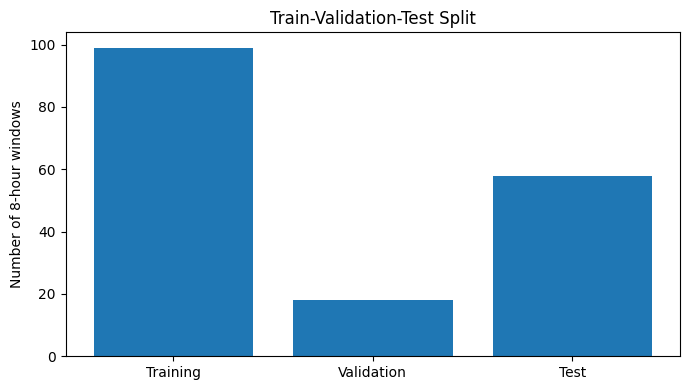

In [ ]:
TEST_FRACTION = 1 / 3
VALIDATION_FRACTION = 0.15
RANDOM_SEED = 42

all_times = valid_windows.to_numpy()
n_times = len(all_times)

# 1. Last one-third of time windows for testing
n_test_times = int(round(n_times * TEST_FRACTION))

pool_times = all_times[:-n_test_times]
test_times = all_times[-n_test_times:]

# 2. Randomly select 15% of training-pool times
rng = np.random.default_rng(RANDOM_SEED)

n_val_times = max(
    1,
    int(round(len(pool_times) * VALIDATION_FRACTION))
)

val_indices = rng.choice(
    len(pool_times),
    size=n_val_times,
    replace=False
)

val_times = pool_times[np.sort(val_indices)]
train_times = np.setdiff1d(pool_times, val_times)

# 3. Create sample masks
train_mask = np.isin(sample_times, train_times)
val_mask = np.isin(sample_times, val_times)
test_mask = np.isin(sample_times, test_times)

assert train_mask.any()
assert val_mask.any()
assert test_mask.any()

assert (
    train_mask.sum() +
    val_mask.sum() +
    test_mask.sum()
) == len(y)

# 4. Split model arrays
X_train = X[train_mask]
y_train = y[train_mask]

X_val = X[val_mask]
y_val = y[val_mask]

X_test = X[test_mask]
y_test = y[test_mask]

# 5. Results
print("DATA SPLIT COMPLETED")

print("\nTime windows:")
print("Training:", len(train_times))
print("Validation:", len(val_times))
print("Test:", len(test_times))

print("\nSamples:")
print("Training:", len(y_train))
print("Validation:", len(y_val))
print("Test:", len(y_test))

print("\nPercentages:")
print(f"Training: {100 * train_mask.mean():.2f}%")
print(f"Validation: {100 * val_mask.mean():.2f}%")
print(f"Test: {100 * test_mask.mean():.2f}%")

print("\nArray shapes:")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

print("\nTest period:")
print(pd.Timestamp(test_times.min()))
print("to")
print(pd.Timestamp(test_times.max()))

# 6. Visualize the split
split_counts = [
    len(train_times),
    len(val_times),
    len(test_times)
]

plt.figure(figsize=(7, 4))
plt.bar(
    ["Training", "Validation", "Test"],
    split_counts
)
plt.ylabel("Number of 8-hour windows")
plt.title("Train-Validation-Test Split")
plt.tight_layout()
plt.show()

## **Step 8: Save the Model-Ready Dataset**

In [ ]:
import json

# Assign split labels to samples
split_labels = np.select(
    [train_mask, val_mask, test_mask],
    ["train", "validation", "test"],
    default="unknown"
)

# Create a complete feature table
model_ready = pd.DataFrame(
    X,
    columns=feature_names
)

model_ready.insert(
    0,
    "window_8h",
    pd.to_datetime(sample_times)
)

model_ready.insert(
    1,
    "station_complex_id",
    sample_stations
)

model_ready["target_ridership"] = y
model_ready["split"] = split_labels

# Save CSV
model_ready.to_csv(
    OUTPUT_DIR / "MTA_model_ready.csv",
    index=False
)

# Save NumPy arrays
np.savez_compressed(
    OUTPUT_DIR / "MTA_model_arrays.npz",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    X_test=X_test,
    y_test=y_test
)

# Record methodological choices
metadata = {
    "number_of_stations": n_stations,
    "number_of_features": X.shape[1],
    "number_of_lags": NUM_LAGS,
    "number_of_usable_windows": n_valid_windows,
    "station_ids": station_ids,
    "test_fraction": TEST_FRACTION,
    "validation_fraction_of_pool": VALIDATION_FRACTION,
    "validation_seed": RANDOM_SEED,
    "temporal_features": [
        "month",
        "day_of_week",
        "time_slot"
    ],
    "aggregation": "Sum ridership per station-hour, then divide 8-hour sum by 8",
    "missing_station_windows": "Filled with zero",
    "feature_scaling": "None",
    "target_scaling": "None",
    "note": "Adapted replication, not verified original preprocessing"
}

with open(
    OUTPUT_DIR / "preprocessing_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Model-ready dataset saved successfully!")

print("\nDataset shape:", model_ready.shape)
print("\nFirst 10 rows:")
display(model_ready.iloc[:10, :15])

print("\nSaved files:")
print("MTA_model_ready.csv")
print("MTA_model_arrays.npz")
print("preprocessing_metadata.json")

Model-ready dataset saved successfully!

Dataset shape: (21175, 134)

First 10 rows:


,window_8h,station_complex_id,month,day_of_week,time_slot,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,station_10,station_103,station_107,station_118
0,2024-11-03 16:00:00,10,11.0,6.0,2.0,835.000,227.125,793.125,891.500,169.750,177.750,1.0,0.0,0.0,0.0
1,2024-11-03 16:00:00,103,11.0,6.0,2.0,101.250,56.625,230.250,137.125,50.250,54.500,0.0,1.0,0.0,0.0
2,2024-11-03 16:00:00,107,11.0,6.0,2.0,118.375,20.375,174.375,155.500,24.375,29.625,0.0,0.0,1.0,0.0
3,2024-11-03 16:00:00,118,11.0,6.0,2.0,282.625,93.000,427.750,229.875,101.625,122.375,0.0,0.0,0.0,1.0
4,2024-11-03 16:00:00,119,11.0,6.0,2.0,548.500,226.500,585.250,627.000,261.125,127.625,0.0,0.0,0.0,0.0
5,2024-11-03 16:00:00,13,11.0,6.0,2.0,439.625,106.750,621.875,447.875,90.125,114.375,0.0,0.0,0.0,0.0
6,2024-11-03 16:00:00,14,11.0,6.0,2.0,594.750,65.625,812.500,695.625,72.125,91.750,0.0,0.0,0.0,0.0
7,2024-11-03 16:00:00,143,11.0,6.0,2.0,242.875,51.875,168.375,315.875,63.625,27.500,0.0,0.0,0.0,0.0
8,2024-11-03 16:00:00,144,11.0,6.0,2.0,212.875,34.625,157.625,253.125,43.750,11.500,0.0,0.0,0.0,0.0
9,2024-11-03 16:00:00,145,11.0,6.0,2.0,175.125,17.000,101.875,186.500,27.625,9.750,0.0,0.0,0.0,0.0



Saved files:
MTA_model_ready.csv
MTA_model_arrays.npz
preprocessing_metadata.json


## **Step 9: Implementation of the Base MLP Neural Network**

In [ ]:

import numpy as np
import torch
import torch.nn as nn

# ==========================================
# 1. CHECK PREPARED DATA
# ==========================================

print("Checking model input data...")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# Check data dimensions
assert X_train.ndim == 2
assert y_train.ndim == 1

assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)
assert X_test.shape[0] == len(y_test)

assert X_train.shape[1] == X_val.shape[1]
assert X_train.shape[1] == X_test.shape[1]

# Check for invalid values
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

assert np.isfinite(y_train).all()
assert np.isfinite(y_val).all()
assert np.isfinite(y_test).all()

assert (y_train >= 0).all()

print("\nData verification passed!")

# ==========================================
# 2. SELECT COMPUTING DEVICE
# ==========================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nComputing device:", device)

# ==========================================
# 3. DEFINE BASE MLP
# ==========================================

class BaseMLP(nn.Module):

    def __init__(self, input_dim):

        super(BaseMLP, self).__init__()

        self.network = nn.Sequential(

            # First hidden layer: 256 neurons
            nn.Linear(input_dim, 256),

            # Layer normalization
            nn.LayerNorm(256),

            # SiLU activation
            nn.SiLU(),

            # Dropout probability = 0.2
            nn.Dropout(p=0.2),

            # Second hidden layer: 128 neurons
            nn.Linear(256, 128),

            # SiLU activation
            nn.SiLU(),

            # Output layer: one predicted value
            nn.Linear(128, 1),

            # Non-negative prediction
            nn.ReLU()
        )

    def forward(self, x):

        output = self.network(x)

        return output.squeeze(-1)

# ==========================================
# 4. INITIALIZE MODEL
# ==========================================

input_dim = X_train.shape[1]

model = BaseMLP(
    input_dim=input_dim
).to(device)

print("\nMODEL ARCHITECTURE:")
print(model)

print("\nNumber of input features:", input_dim)

# ==========================================
# 5. COUNT TRAINABLE PARAMETERS
# ==========================================

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

# ==========================================
# 6. TEST THE MODEL
# ==========================================

# Take five samples from the training set
sample_input = torch.tensor(
    X_train[:5],
    dtype=torch.float32
).to(device)

# Evaluation mode disables dropout
model.eval()

with torch.no_grad():

    sample_predictions = model(
        sample_input
    )

print("\nSample input shape:")
print(sample_input.shape)

print("\nSample output shape:")
print(sample_predictions.shape)

print("\nSample predictions:")
print(
    sample_predictions.cpu().numpy()
)

# ==========================================
# 7. VERIFY OUTPUT
# ==========================================

assert sample_predictions.shape == (5,)

assert torch.isfinite(
    sample_predictions
).all()

assert (
    sample_predictions >= 0
).all()

print("\nBASE MLP IMPLEMENTATION SUCCESSFUL!")

Checking model input data...
X_train shape: (11979, 130)
y_train shape: (11979,)
X_val shape: (2178, 130)
y_val shape: (2178,)
X_test shape: (7018, 130)
y_test shape: (7018,)

Data verification passed!

Computing device: cpu

MODEL ARCHITECTURE:
BaseMLP(
  (network): Sequential(
    (0): Linear(in_features=130, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
    (2): SiLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=1, bias=True)
    (7): ReLU()
  )
)

Number of input features: 130

Total parameters: 67073
Trainable parameters: 67073

Sample input shape:
torch.Size([5, 130])

Sample output shape:
torch.Size([5])

Sample predictions:
[0. 0. 0. 0. 0.]

BASE MLP IMPLEMENTATION SUCCESSFUL!


## **Step 10: Training the Predict-Then-Optimize (PTO) Baseline**

Training device: cpu
Training epochs: 500
Independent runs: 5
Training: 11979 samples, 130 features
Validation: 2178 samples, 130 features
Test: 7018 samples, 130 features

STARTING PTO TRAINING - SEED 0
Epoch   1/500 | Train Huber: 278.01018 | Val Huber: 203.70891 | Val MAE: 204.20680 | LR: 0.010000
Epoch  25/500 | Train Huber: 62.78231 | Val Huber: 89.17477 | Val MAE: 89.67245 | LR: 0.010000
Epoch  50/500 | Train Huber: 54.40316 | Val Huber: 75.24130 | Val MAE: 75.73762 | LR: 0.005000
Epoch  75/500 | Train Huber: 51.86765 | Val Huber: 72.40345 | Val MAE: 72.89828 | LR: 0.000625
Epoch 100/500 | Train Huber: 50.86164 | Val Huber: 70.62746 | Val MAE: 71.12268 | LR: 0.000156
Epoch 125/500 | Train Huber: 50.56638 | Val Huber: 69.65729 | Val MAE: 70.15275 | LR: 0.000010
Epoch 150/500 | Train Huber: 50.59897 | Val Huber: 69.61994 | Val MAE: 70.11565 | LR: 0.000001
Epoch 175/500 | Train Huber: 50.79270 | Val Huber: 69.62365 | Val MAE: 70.11940 | LR: 0.000000
Epoch 200/500 | Train Huber: 50.5

,seed,training_MAE,validation_MAE,test_MAE,test_Huber
0,0,46.545665,70.120448,59.342970,58.847490
1,1,47.183396,71.136578,59.541708,59.045774
2,2,46.646292,69.910797,59.329309,58.833600
3,3,46.168027,70.159914,59.091802,58.596455
4,4,46.690564,70.339929,59.073485,58.578029



FINAL TEST MAE
Mean MAE: 59.275855
Standard deviation: 0.195492


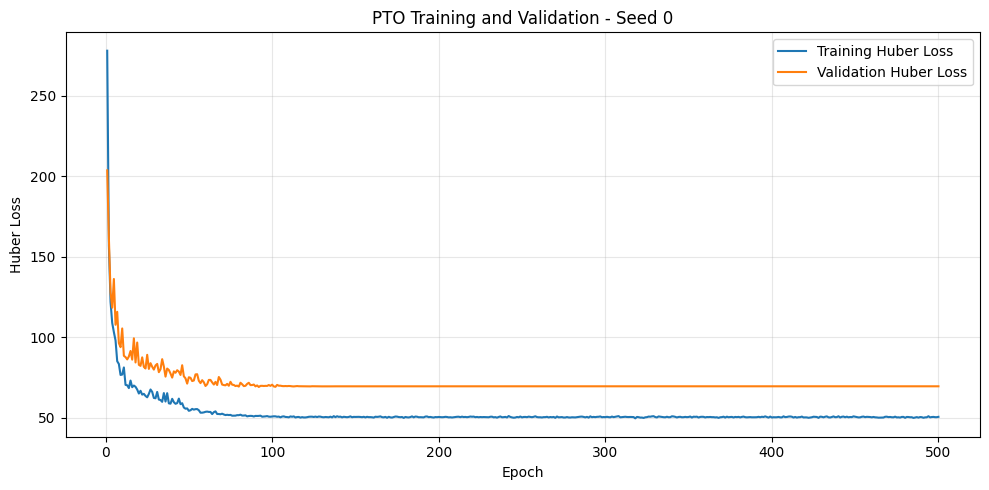


Files saved in: /content/NYC_Subway_Results
STEP 10 COMPLETED SUCCESSFULLY


In [ ]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from pathlib import Path

# ============================================================
# 1. TRAINING CONFIGURATION
# ============================================================

EPOCHS = 500
SEEDS = [0, 1, 2, 3, 4]

LEARNING_RATE = 0.01
WEIGHT_DECAY = 0.01

INPUT_NOISE_STD = 0.01

SCHEDULER_FACTOR = 0.5
SCHEDULER_PATIENCE = 5

# Implementation choices: not specified in the paper
BATCH_SIZE = 256
HUBER_DELTA = 1.0

OUTPUT_DIR = Path("/content/NYC_Subway_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training device:", device)
print("Training epochs:", EPOCHS)
print("Independent runs:", len(SEEDS))

# ============================================================
# 2. VERIFY INPUT DATA
# ============================================================

for name, features, targets in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:

    assert len(features) == len(targets)
    assert features.ndim == 2
    assert targets.ndim == 1

    assert features.shape[1] == X_train.shape[1]

    assert np.isfinite(features).all()
    assert np.isfinite(targets).all()

    assert (targets >= 0).all()

    print(
        f"{name}: {len(targets)} samples, "
        f"{features.shape[1]} features"
    )

# Convert to contiguous float32 arrays
X_train_t = torch.from_numpy(
    np.ascontiguousarray(X_train, dtype=np.float32)
)
y_train_t = torch.from_numpy(
    np.ascontiguousarray(y_train, dtype=np.float32)
)

X_val_t = torch.from_numpy(
    np.ascontiguousarray(X_val, dtype=np.float32)
)
y_val_t = torch.from_numpy(
    np.ascontiguousarray(y_val, dtype=np.float32)
)

X_test_t = torch.from_numpy(
    np.ascontiguousarray(X_test, dtype=np.float32)
)
y_test_t = torch.from_numpy(
    np.ascontiguousarray(y_test, dtype=np.float32)
)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

# ============================================================
# 3. SET RANDOM SEEDS
# ============================================================

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ============================================================
# 4. EVALUATION FUNCTION
# ============================================================

# Evaluates a model without updating its weights.
# No Gaussian noise and no active dropout during evaluation.

def evaluate_model(model, dataset):

    loader = DataLoader(
        dataset,
        batch_size=1024,
        shuffle=False
    )

    model.eval()

    huber_sum = 0.0
    absolute_error_sum = 0.0
    n_samples = 0

    all_predictions = []

    with torch.no_grad():

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = model(batch_X)

            # Sum Huber errors over this batch
            batch_huber = nn.functional.huber_loss(
                predictions,
                batch_y,
                delta=HUBER_DELTA,
                reduction="sum"
            )

            huber_sum += batch_huber.item()

            absolute_error_sum += (
                torch.abs(predictions - batch_y)
                .sum()
                .item()
            )

            n_samples += len(batch_y)

            all_predictions.append(
                predictions.cpu().numpy()
            )

    return {
        "huber": huber_sum / n_samples,
        "mae": absolute_error_sum / n_samples,
        "predictions": np.concatenate(all_predictions)
    }

# ============================================================
# 5. PREPARE RESULT STORAGE
# ============================================================

training_history = []
experiment_results = []

test_predictions_by_seed = {}

# ============================================================
# 6. RUN FIVE INDEPENDENT TRAINING EXPERIMENTS
# ============================================================

for seed in SEEDS:

    print("\n" + "=" * 60)
    print(f"STARTING PTO TRAINING - SEED {seed}")
    print("=" * 60)

    # ----------------------------------------
    # 6.1 Set random seed
    # ----------------------------------------

    set_seed(seed)

    # ----------------------------------------
    # 6.2 Initialize a NEW neural network
    # ----------------------------------------

    model = BaseMLP(
        input_dim=X_train.shape[1]
    ).to(device)

    # ----------------------------------------
    # 6.3 Define Huber loss
    # ----------------------------------------

    criterion = nn.HuberLoss(
        delta=HUBER_DELTA
    )

    # ----------------------------------------
    # 6.4 Define AdamW optimizer
    # ----------------------------------------

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    # ----------------------------------------
    # 6.5 Learning-rate scheduler
    # ----------------------------------------

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=SCHEDULER_FACTOR,
        patience=SCHEDULER_PATIENCE
    )

    # ----------------------------------------
    # 6.6 Create shuffled training batches
    # ----------------------------------------

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    # ========================================================
    # 7. TRAINING EPOCH LOOP
    # ========================================================

    for epoch in range(1, EPOCHS + 1):

        # Enable training mode and dropout
        model.train()

        epoch_loss_sum = 0.0
        epoch_samples = 0

        # ----------------------------------------------------
        # 7.1 PROCESS EVERY TRAINING BATCH
        # ----------------------------------------------------

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            # Gaussian input noise:
            # epsilon ~ N(0, 0.01^2 I)
            noise = (
                torch.randn_like(batch_X)
                * INPUT_NOISE_STD
            )

            noisy_X = batch_X + noise

            # Clear gradients from previous batch
            optimizer.zero_grad(set_to_none=True)

            # Forward pass
            predictions = model(noisy_X)

            # Calculate supervised Huber loss
            loss = criterion(
                predictions,
                batch_y
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    f"Non-finite loss at seed={seed}, "
                    f"epoch={epoch}"
                )

            # Backpropagation
            loss.backward()

            # Update neural network weights
            optimizer.step()

            # Accumulate training loss
            batch_n = len(batch_y)

            epoch_loss_sum += (
                loss.item() * batch_n
            )

            epoch_samples += batch_n

        # ----------------------------------------------------
        # 7.2 COMPUTE TRAINING LOSS
        # ----------------------------------------------------

        train_huber = (
            epoch_loss_sum / epoch_samples
        )

        # ----------------------------------------------------
        # 7.3 COMPUTE VALIDATION LOSS
        # ----------------------------------------------------

        validation_result = evaluate_model(
            model,
            val_dataset
        )

        val_huber = validation_result["huber"]
        val_mae = validation_result["mae"]

        # ----------------------------------------------------
        # 7.4 UPDATE LEARNING RATE
        # ----------------------------------------------------

        scheduler.step(val_huber)

        current_lr = (
            optimizer.param_groups[0]["lr"]
        )

        # ----------------------------------------------------
        # 7.5 SAVE EPOCH HISTORY
        # ----------------------------------------------------

        training_history.append({

            "seed": seed,
            "epoch": epoch,
            "training_huber": train_huber,
            "validation_huber": val_huber,
            "validation_mae": val_mae,
            "learning_rate": current_lr

        })

        # ----------------------------------------------------
        # 7.6 PRINT PROGRESS
        # ----------------------------------------------------

        if (
            epoch == 1
            or epoch % 25 == 0
            or epoch == EPOCHS
        ):

            print(
                f"Epoch {epoch:3d}/{EPOCHS} | "
                f"Train Huber: {train_huber:.5f} | "
                f"Val Huber: {val_huber:.5f} | "
                f"Val MAE: {val_mae:.5f} | "
                f"LR: {current_lr:.6f}"
            )

    # ========================================================
    # 8. FINAL EVALUATION AFTER 500 EPOCHS
    # ========================================================

    final_train = evaluate_model(
        model,
        train_dataset
    )

    final_val = evaluate_model(
        model,
        val_dataset
    )

    final_test = evaluate_model(
        model,
        test_dataset
    )

    # The test set is used only after training.
    # PTO uses predictive loss, not strategic utility,
    # to train this baseline.

    experiment_results.append({

        "seed": seed,

        "training_MAE": final_train["mae"],

        "validation_MAE": final_val["mae"],

        "test_MAE": final_test["mae"],

        "test_Huber": final_test["huber"]

    })

    test_predictions_by_seed[seed] = (
        final_test["predictions"]
    )

    print("\nFINAL RESULTS FOR THIS SEED")

    print(
        f"Training MAE: "
        f"{final_train['mae']:.6f}"
    )

    print(
        f"Validation MAE: "
        f"{final_val['mae']:.6f}"
    )

    print(
        f"Test MAE: "
        f"{final_test['mae']:.6f}"
    )

    # Check whether predictions collapsed to zero
    zero_fraction = float(
        np.mean(final_test["predictions"] == 0)
    )

    if zero_fraction > 0.95:

        print(
            "WARNING: More than 95% of test "
            "predictions are zero."
        )

        print(
            "Inspect the model before interpreting "
            "its performance."
        )

    # ========================================================
    # 9. SAVE FINAL MODEL WEIGHTS
    # ========================================================

    model_path = (
        OUTPUT_DIR / f"PTO_model_seed_{seed}.pt"
    )

    torch.save({

        "model_state_dict": model.state_dict(),

        "input_dim": X_train.shape[1],

        "seed": seed,

        "epochs": EPOCHS,

        "learning_rate": LEARNING_RATE,

        "weight_decay": WEIGHT_DECAY,

        "batch_size": BATCH_SIZE,

        "huber_delta": HUBER_DELTA,

        "input_noise_std": INPUT_NOISE_STD

    }, model_path)

    print("Model saved:", model_path.name)

# ============================================================
# 10. SUMMARIZE ALL FIVE RUNS
# ============================================================

history_df = pd.DataFrame(
    training_history
)

results_df = pd.DataFrame(
    experiment_results
)

print("\n" + "=" * 60)
print("PTO TRAINING COMPLETED")
print("=" * 60)

display(results_df)

# Report mean and standard deviation
print("\nFINAL TEST MAE")

mean_mae = results_df["test_MAE"].mean()

print(f"Mean MAE: {mean_mae:.6f}")

if len(results_df) > 1:

    std_mae = results_df["test_MAE"].std(ddof=1)

    print(f"Standard deviation: {std_mae:.6f}")

# ============================================================
# 11. SAVE EXPERIMENT RESULTS
# ============================================================

history_df.to_csv(
    OUTPUT_DIR / "PTO_training_history.csv",
    index=False
)

results_df.to_csv(
    OUTPUT_DIR / "PTO_final_results.csv",
    index=False
)

np.savez_compressed(
    OUTPUT_DIR / "PTO_test_predictions.npz",
    **{
        f"seed_{seed}": prediction
        for seed, prediction
        in test_predictions_by_seed.items()
    }
)

# ============================================================
# 12. PLOT TRAINING AND VALIDATION LOSS
# ============================================================

first_seed = SEEDS[0]

first_history = history_df[
    history_df["seed"] == first_seed
]

plt.figure(figsize=(10, 5))

plt.plot(
    first_history["epoch"],
    first_history["training_huber"],
    label="Training Huber Loss"
)

plt.plot(
    first_history["epoch"],
    first_history["validation_huber"],
    label="Validation Huber Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Huber Loss")

plt.title(
    f"PTO Training and Validation - Seed {first_seed}"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "PTO_training_curve.png",
    dpi=200
)

plt.show()

print("\nFiles saved in:", OUTPUT_DIR)
print("STEP 10 COMPLETED SUCCESSFULLY")